# PHẦN 4: PHÂN TÍCH TƯƠNG QUAN GIỮA CÁC BIẾN

**Bộ dữ liệu:** Medical Cost Personal Datasets (Kaggle: `mirichoi0218/insurance`), gồm 1338 bản ghi và 7 biến.

**Nội dung thực hiện:**

- **4.0** Chuẩn bị dữ liệu
- **4.1** Cơ sở lý thuyết về hệ số tương quan Pearson và Spearman
- **4.2** Tính hệ số tương quan Pearson và Spearman trên bộ dữ liệu
- **4.3** Trực quan hoá mối quan hệ giữa các biến
- **4.4** Nhận xét về ý nghĩa thực tiễn của các mối tương quan

## 4.0. Chuẩn bị dữ liệu

**Mục đích:** nạp bộ dữ liệu `insurance.csv` vào bảng `df`, kiểm tra cấu trúc dữ liệu và chuẩn bị các biến số cho phân tích tương quan.

**Giải thích các lệnh chính:**

- `pd.read_csv(...)`: đọc file CSV thành một bảng dữ liệu (DataFrame).
- `df.shape`: trả về (số dòng, số cột) để biết quy mô dữ liệu.
- `df.dtypes`: cho biết kiểu dữ liệu của từng cột (số nguyên, số thực hay chữ).
- `(df["smoker"] == "yes").astype(int)`: phép so sánh trả về cột True/False cho từng dòng, sau đó `.astype(int)` đổi True thành 1 và False thành 0.

**Vì sao phải mã hoá `smoker` và `sex` thành 0/1?**
Hệ số Pearson và Spearman chỉ tính được giữa các **biến số**. Hai biến `smoker` ("yes"/"no") và `sex` ("male"/"female") đang là chữ nhưng chỉ có **2 giá trị** (biến nhị phân), nên ta có thể mã hoá thành số:

- `smoker_num`: yes = 1, no = 0
- `sex_num`: male = 1, female = 0

Hệ số tương quan giữa biến nhị phân 0/1 và biến liên tục gọi là **hệ số tương quan điểm-nhị phân (point-biserial)**, về bản chất vẫn là hệ số Pearson. **Dấu của hệ số phụ thuộc vào cách mã hoá**: ví dụ r > 0 giữa `sex_num` và `charges` nghĩa là nam có chi phí cao hơn nữ.

**Vì sao chưa đưa `region` vào?**
`region` có 4 giá trị không có thứ tự tự nhiên. Nếu gán 0, 1, 2, 3 sẽ tạo ra một thứ tự giả (ví dụ coi southeast "lớn hơn" northeast), làm kết quả tương quan mất ý nghĩa. Ảnh hưởng của `region` sẽ được xét ở phần kiểm định giả thuyết (ANOVA) và hồi quy (biến giả).

**Các biến dùng để phân tích tương quan:** `age`, `bmi`, `children`, `sex_num`, `smoker_num`, `charges`.

In [19]:
# Import pandas để làm việc với dữ liệu dạng bảng (DataFrame)
import pandas as pd

# Đọc file CSV (".." = đi lên một thư mục, rồi vào thư mục shared)
df = pd.read_csv("../shared/insurance.csv")

# In kích thước bảng dữ liệu: (số dòng, số cột)
print(df.shape)

# In kiểu dữ liệu của từng cột (số hay chữ)
print(df.dtypes)

# Tạo cột mới smoker_num: bằng 1 nếu smoker là "yes", ngược lại bằng 0
df["smoker_num"] = (df["smoker"] == "yes").astype(int)

# Tạo cột mới sex_num: bằng 1 nếu sex là "male", ngược lại (female) bằng 0
df["sex_num"] = (df["sex"] == "male").astype(int)

# Danh sách các biến sẽ dùng để tính tương quan (region không đưa vào vì có 4 nhóm không có thứ tự)
CAC_BIEN = ["age", "bmi", "children", "sex_num", "smoker_num", "charges"]

# Đếm số giá trị 0 và 1 trong smoker_num để kiểm tra việc mã hoá có đúng không
print(df["smoker_num"].value_counts())

# Đếm số giá trị 0 và 1 trong sex_num để kiểm tra việc mã hoá có đúng không
print(df["sex_num"].value_counts())

(1338, 7)
age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object
smoker_num
0    1064
1     274
Name: count, dtype: int64
sex_num
1    676
0    662
Name: count, dtype: int64


**Nhận xét kết quả:**

- Bộ dữ liệu có **1338 dòng và 7 cột**, đáp ứng yêu cầu tối thiểu (500 dòng, 5 biến).
- `age`, `children` là số nguyên; `bmi`, `charges` là số thực; `sex`, `smoker`, `region` là biến phân loại (dạng chữ).
- `smoker_num` có **1064 người không hút thuốc (0)** và **274 người hút thuốc (1)**, tức khoảng 20% là người hút thuốc.
- `sex_num` có số nam và số nữ gần bằng nhau (xem output), nên dữ liệu **cân bằng về giới tính**.
- Với mỗi biến, tổng hai nhóm bằng 1338, khớp số dòng nên việc mã hoá không làm mất dữ liệu.

## 4.1. Cơ sở lý thuyết

### 4.1.1. Hệ số tương quan Pearson

**Mục đích:** tự tính tay hệ số Pearson trên 5 điểm dữ liệu để hiểu công thức hoạt động như thế nào, trước khi dùng hàm có sẵn trên dữ liệu thật.

**Công thức:**

$$
r = \frac{\sum (x_i-\bar{x})(y_i-\bar{y})}{\sqrt{\sum (x_i-\bar{x})^2 \cdot \sum (y_i-\bar{y})^2}}
$$

**Ý nghĩa từng thành phần:**

1. **Độ lệch** $dx_i = x_i-\bar{x}$ và $dy_i = y_i-\bar{y}$: cho biết mỗi điểm nằm trên hay dưới trung bình của biến đó.
2. **Tích của hai độ lệch** $dx_i \cdot dy_i$: dương khi hai biến cùng nằm trên (hoặc cùng nằm dưới) trung bình; âm khi một biến ở trên còn biến kia ở dưới; bằng 0 khi có một biến đúng bằng trung bình.
3. **Tử số (tổng các tích):** tổng dương lớn cho thấy các điểm lệch xa trung bình chủ yếu **cùng chiều** nhau; tổng âm lớn cho thấy chủ yếu **ngược chiều** nhau. Lưu ý điểm nào lệch càng xa trung bình thì đóng góp càng nhiều, nên vài điểm ngoại lai cũng có thể chi phối kết quả.
4. **Mẫu số:** dùng để **chuẩn hoá**, giúp r không phụ thuộc vào đơn vị đo và luôn nằm trong đoạn $[-1, 1]$.

**Cách đọc giá trị r:**

- $r > 0$: tương quan dương (cùng tăng, cùng giảm); $r < 0$: tương quan âm.
- $|r|$ càng gần 1 thì quan hệ **tuyến tính** càng mạnh; $r = \pm 1$ khi các điểm nằm đúng trên một đường thẳng.
- $r \approx 0$ chỉ cho biết **không có quan hệ tuyến tính**, vẫn có thể tồn tại quan hệ phi tuyến (ví dụ hình chữ U).

**Giải thích các lệnh chính:**

- `np.array([...])`: tạo mảng số để tính toán trên cả dãy cùng lúc.
- `x.mean()`: tính giá trị trung bình.
- `dx * dy`: nhân từng phần tử tương ứng của hai mảng.
- `.sum()`: cộng tất cả phần tử.
- `np.sqrt(...)`: căn bậc hai.
- `np.corrcoef(x, y)[0, 1]`: hàm có sẵn của numpy trả về ma trận 2x2, phần tử `[0, 1]` chính là r giữa x và y, dùng để đối chiếu với kết quả tính tay.

In [20]:
# Import numpy để tính toán trên mảng số
import numpy as np

# Biến x gồm 5 giá trị
x = np.array([1, 2, 3, 4, 5])
# Biến y gồm 5 giá trị
y = np.array([2, 4, 5, 4, 5])

# Tính trung bình của x và của y
x_tb = x.mean()
y_tb = y.mean()
# In hai giá trị trung bình
print("Trung bình x:", x_tb, "| Trung bình y:", y_tb)

# Độ lệch của từng điểm so với trung bình (dương = trên trung bình, âm = dưới trung bình)
dx = x - x_tb
dy = y - y_tb
# In độ lệch để quan sát dấu
print("dx:", dx)
print("dy:", dy)

# Tích từng cặp độ lệch: dương nếu cùng phía so với trung bình, âm nếu khác phía
tich = dx * dy
# In các tích này
print("dx * dy:", tich)

# Tử số = tổng các tích
tu_so = tich.sum()
# Mẫu số = căn bậc hai của (tổng dx bình phương) nhân (tổng dy bình phương)
mau_so = np.sqrt((dx ** 2).sum() * (dy ** 2).sum())
# In tử số và mẫu số
print("Tử số:", tu_so, "| Mẫu số:", round(mau_so, 4))

# Hệ số tương quan Pearson r = tử số / mẫu số
r = tu_so / mau_so
# In kết quả tính tay
print("r tính tay:", round(r, 4))

# Đối chiếu với hàm có sẵn của numpy (phần tử [0, 1] của ma trận 2x2 chính là r)
print("r numpy   :", round(np.corrcoef(x, y)[0, 1], 4))

Trung bình x: 3.0 | Trung bình y: 4.0
dx: [-2. -1.  0.  1.  2.]
dy: [-2.  0.  1.  0.  1.]
dx * dy: [ 4. -0.  0.  0.  2.]
Tử số: 6.0 | Mẫu số: 7.746
r tính tay: 0.7746
r numpy   : 0.7746


**Nhận xét kết quả:**

- Trung bình của x là 3 và của y là 4.
- Điểm đầu tiên ($x=1$, $y=2$) cùng nằm **dưới** trung bình nên tích $(-2)\times(-2)=+4$, đóng góp làm tăng r.
- Ba điểm có tích bằng 0: hai điểm có $dy=0$ (y đúng bằng trung bình) và một điểm có $dx=0$ (x đúng bằng trung bình), nên không đóng góp vào tử số.
- Tử số bằng 6, mẫu số bằng $\sqrt{10 \times 6}\approx 7{,}746$, nên $r \approx 0{,}775$.
- Kết quả tính tay **trùng khớp** với `np.corrcoef`, chứng tỏ hàm có sẵn chỉ là cách viết gọn của công thức trên.
- $r \approx 0{,}775$ cho thấy trong 5 điểm này, x tăng thì y có xu hướng tăng theo (tương quan dương). Tuy nhiên với cỡ mẫu chỉ $n=5$, kết quả này **chưa đủ cơ sở thống kê** để suy ra cho tổng thể (kiểm định cho p-value khoảng 0,12). Ví dụ chỉ nhằm minh hoạ cách tính.

### 4.1.2. Hệ số tương quan hạng Spearman

**Ý tưởng:** Spearman **không dùng giá trị gốc mà dùng thứ hạng**. Cách làm:

1. Xếp hạng các giá trị của $X$ (nhỏ nhất = hạng 1) và xếp hạng các giá trị của $Y$, độc lập với nhau.
2. Tính hệ số Pearson trên hai dãy hạng này.

Khi **không có giá trị trùng nhau**, có công thức rút gọn:

$$
\rho_s = 1 - \frac{6\sum d_i^2}{n(n^2-1)}, \qquad d_i = \text{hạng}(x_i) - \text{hạng}(y_i)
$$

Nếu có giá trị trùng, các giá trị đó nhận **hạng trung bình** (ví dụ hai giá trị cùng chiếm hạng 3 và 4 thì mỗi giá trị nhận hạng 3.5) và dùng định nghĩa "Pearson trên hạng".

**Spearman đo gì?** Đo quan hệ **đơn điệu**: khi X tăng thì Y luôn có xu hướng tăng (hoặc luôn giảm), **không cần là đường thẳng**.

**Vì sao cần Spearman bên cạnh Pearson?**

- **Bền vững với ngoại lai:** một giá trị cực lớn chỉ là "hạng cuối", không kéo kết quả đi xa.
- **Không đòi hỏi phân phối chuẩn:** phù hợp với biến lệch như `charges`.
- **Phù hợp với biến đếm rời rạc** có nhiều giá trị trùng như `children`.

**Giải thích các lệnh chính:**

- `stats.rankdata(...)`: xếp hạng các giá trị (tự xử lý giá trị trùng bằng hạng trung bình).
- `d ** 2`: bình phương từng hiệu hạng.
- `stats.spearmanr(x, y)`: hàm có sẵn của SciPy, trả về (hệ số Spearman, p-value).

In [21]:
# Import numpy để tính toán trên mảng số
import numpy as np
# Import module thống kê của SciPy (rankdata, spearmanr, pearsonr)
from scipy import stats

# Biến x gồm 5 giá trị tăng dần
x2 = np.array([10, 20, 30, 40, 50])
# Biến y gồm 5 giá trị không tăng đều theo x
y2 = np.array([3, 1, 4, 2, 5])

# Xếp hạng x (giá trị nhỏ nhất nhận hạng 1)
hang_x = stats.rankdata(x2)
# Xếp hạng y, độc lập với x
hang_y = stats.rankdata(y2)
# In hai dãy hạng để quan sát
print("Hạng x:", hang_x, "| Hạng y:", hang_y)

# Hiệu hạng d của từng cặp điểm
d = hang_x - hang_y
# Bình phương hiệu hạng (để mọi giá trị đều không âm)
d2 = d ** 2
# In d và d bình phương để thấy từng bước
print("d:", d, "| d^2:", d2, "| tổng d^2:", d2.sum())

# Số quan sát n
n = len(x2)
# Áp dụng công thức rút gọn: rho = 1 - 6 * tổng(d^2) / (n * (n^2 - 1))
rho_tay = 1 - 6 * d2.sum() / (n * (n ** 2 - 1))
# In kết quả tính tay
print("Spearman tính tay:", round(rho_tay, 4))

# Kiểm tra theo định nghĩa: Pearson tính trên hai dãy hạng
print("Pearson trên hạng:", round(np.corrcoef(hang_x, hang_y)[0, 1], 4))
# Đối chiếu với hàm có sẵn của SciPy (lấy phần tử đầu tiên là hệ số)
print("SciPy spearmanr  :", round(stats.spearmanr(x2, y2)[0], 4))

# ----- Ví dụ 2: quan hệ cong nhưng luôn tăng -----
# x chạy từ 1 đến 10
xa = np.arange(1, 11)
# y = x bình phương: tăng nhanh dần, không phải đường thẳng
ya = xa ** 2
# So sánh Pearson và Spearman trên quan hệ cong này
print("\ny = x^2 -> Pearson:", round(stats.pearsonr(xa, ya)[0], 4),
      "| Spearman:", round(stats.spearmanr(xa, ya)[0], 4))

Hạng x: [1. 2. 3. 4. 5.] | Hạng y: [3. 1. 4. 2. 5.]
d: [-2.  1. -1.  2.  0.] | d^2: [4. 1. 1. 4. 0.] | tổng d^2: 10.0
Spearman tính tay: 0.5
Pearson trên hạng: 0.5
SciPy spearmanr  : 0.5

y = x^2 -> Pearson: 0.9746 | Spearman: 1.0


**Nhận xét kết quả:**

- Hạng của $x$ là $[1, 2, 3, 4, 5]$, hạng của $y$ là $[3, 1, 4, 2, 5]$, nên hiệu hạng $d = [-2, 1, -1, 2, 0]$ và $\sum d^2 = 10$.
- Công thức rút gọn cho $\rho_s = 1 - \dfrac{6 \times 10}{5 \times 24} = 0{,}5$. Kết quả này **trùng** với "Pearson tính trên hạng" và hàm `spearmanr`, xác nhận đúng định nghĩa: **Spearman là Pearson của các thứ hạng**.
- Với quan hệ cong $y = x^2$: Spearman $= 1$ (vì $y$ luôn tăng khi $x$ tăng, thứ hạng hoàn toàn giống nhau), trong khi Pearson $\approx 0{,}975 < 1$ (vì quan hệ không phải đường thẳng). Spearman nhận ra quan hệ **đơn điệu** mà Pearson chỉ nhận ra một phần.
- Spearman chỉ dựa vào thứ hạng nên **không bị ảnh hưởng bởi độ lớn** của ngoại lai: đổi giá trị lớn nhất của một biến thành số rất lớn thì thứ hạng vẫn không đổi.

## 4.2. Tính hệ số tương quan trên bộ dữ liệu

### 4.2.1. Ma trận tương quan Pearson

**Mục đích:** tính hệ số Pearson cho **mọi cặp biến** trong `CAC_BIEN` cùng một lúc, thay vì tính tay từng cặp như ở ví dụ 5 điểm.

**Giải thích lệnh:**

- `df[CAC_BIEN]`: chọn ra các cột số cần tính tương quan.
- `.corr(method="pearson")`: tính hệ số Pearson cho từng cặp cột, kết quả là một **ma trận vuông**. Mỗi ô là kết quả của đúng công thức đã tính tay ở mục 4.1.1, nhưng áp dụng trên 1338 dòng.
- `.round(3)`: làm tròn 3 chữ số thập phân cho dễ đọc.

**Cách đọc ma trận:**

- Giao của một hàng và một cột cho biết hệ số tương quan của cặp biến đó.
- **Đường chéo luôn bằng 1:** một biến tương quan hoàn hảo với chính nó.
- **Ma trận đối xứng:** $r(X,Y) = r(Y,X)$, nên chỉ cần đọc một nửa tam giác.
- Cần chú ý nhất **hàng/cột `charges`**, vì đây là biến mục tiêu cho phần hồi quy.

In [22]:
# Tính ma trận tương quan Pearson cho tất cả các biến trong CAC_BIEN
ma_tran_pearson = df[CAC_BIEN].corr(method="pearson")

# In ma trận, làm tròn 3 chữ số thập phân
print(ma_tran_pearson.round(3))

# Lấy riêng cột charges, bỏ dòng charges - charges (luôn bằng 1)
# rồi sắp xếp theo độ lớn (giá trị tuyệt đối) giảm dần để thấy biến nào liên quan nhất
print("\nTương quan Pearson với charges (sắp xếp theo độ mạnh):")
print(ma_tran_pearson["charges"].drop("charges").sort_values(key=abs, ascending=False).round(3))

              age    bmi  children  sex_num  smoker_num  charges
age         1.000  0.109     0.042   -0.021      -0.025    0.299
bmi         0.109  1.000     0.013    0.046       0.004    0.198
children    0.042  0.013     1.000    0.017       0.008    0.068
sex_num    -0.021  0.046     0.017    1.000       0.076    0.057
smoker_num -0.025  0.004     0.008    0.076       1.000    0.787
charges     0.299  0.198     0.068    0.057       0.787    1.000

Tương quan Pearson với charges (sắp xếp theo độ mạnh):
smoker_num    0.787
age           0.299
bmi           0.198
children      0.068
sex_num       0.057
Name: charges, dtype: float64


**Nhận xét kết quả (Pearson):**

**1. Tương quan giữa các biến với `charges`:**

| Biến | Pearson r | R² | Mức độ |
|---|---|---|---|
| `smoker_num` | 0,787 | ≈ 0,62 | Mạnh, dương |
| `age` | 0,299 | ≈ 0,09 | Yếu (sát ngưỡng trung bình), dương |
| `bmi` | 0,198 | ≈ 0,04 | Yếu, dương |
| `children` | 0,068 | ≈ 0,005 | Gần như không có |
| `sex_num` | 0,057 | ≈ 0,003 | Gần như không có |

- `smoker_num` là biến có tương quan **mạnh nhất**: riêng việc có hút thuốc hay không giải thích khoảng **62%** biến thiên (tuyến tính) của chi phí y tế. Vì `smoker_num` mã hoá yes = 1, r dương nghĩa là người hút thuốc có chi phí cao hơn.
- `age` có tương quan dương yếu: tuổi càng cao thì chi phí có xu hướng tăng, nhưng quan hệ tuyến tính chỉ giải thích khoảng 9% biến thiên.
- `bmi` chỉ giải thích khoảng 4% biến thiên của chi phí khi xét gộp chung.
- `children` và `sex_num` gần như không liên quan tới `charges` (R² dưới 1%). Với `sex_num` (male = 1), r dương rất nhỏ nghĩa là nam có chi phí nhỉnh hơn nữ một chút, không đáng kể.

**2. Tương quan giữa các biến độc lập với nhau:**

- Mọi hệ số giữa các biến độc lập đều **rất thấp** (lớn nhất là `age`–`bmi` = 0,109, tiếp theo là `sex_num`–`smoker_num` = 0,076). Các biến này mang thông tin gần như **độc lập** nhau, nên nguy cơ **đa cộng tuyến** thấp, thuận lợi cho hồi quy đa biến ở phần sau.
- Hệ số `sex_num`–`smoker_num` dương nhỏ cho thấy nam hút thuốc nhỉnh hơn nữ một chút, nên một phần tương quan nhỏ giữa giới tính và chi phí có thể đến từ việc hút thuốc.

**3. Lưu ý:**

- Đây mới là hệ số **Pearson**, chỉ đo quan hệ **tuyến tính** và nhạy với ngoại lai (`charges` có phân phối lệch phải). Cần so sánh thêm với Spearman.
- Ta chưa kiểm định ý nghĩa thống kê (p-value). Tương quan nhỏ như 0,057 chưa chắc khác 0 một cách đáng tin cậy.
- Tương quan không đồng nghĩa với nhân quả.

### 4.2.2. Ma trận tương quan Spearman và so sánh với Pearson

**Mục đích:** tính hệ số Spearman cho mọi cặp biến, rồi **so sánh với Pearson** (mục 4.2.1) để biết quan hệ giữa các biến gần tuyến tính hay chỉ đơn điệu, và có bị ngoại lai chi phối không.

**Giải thích lệnh:**

- `.corr(method="spearman")`: pandas tự xếp hạng từng cột (giá trị trùng nhận hạng trung bình) rồi tính Pearson trên các hạng đó.
- `pd.DataFrame({...})`: ghép hai cột kết quả (Pearson và Spearman) thành một bảng để đặt cạnh nhau.
- `.drop("charges")`: bỏ dòng `charges` với chính nó (luôn bằng 1).
- Cột `Spearman - Pearson`: hiệu của hai hệ số, giúp thấy ngay biến nào có hai hệ số chênh lệch nhiều.

**Cách đọc chênh lệch:**

- **Pearson ≈ Spearman:** quan hệ gần tuyến tính, ít bị ngoại lai chi phối.
- **Spearman > Pearson:** quan hệ cùng chiều nhưng không thẳng, hoặc ngoại lai đang làm yếu Pearson.
- **Pearson > Spearman:** tương quan chủ yếu do một số ít điểm cực trị tạo ra.

In [23]:
# Tính ma trận tương quan Spearman cho tất cả các biến trong CAC_BIEN
ma_tran_spearman = df[CAC_BIEN].corr(method="spearman")

# In ma trận Spearman, làm tròn 3 chữ số thập phân
print(ma_tran_spearman.round(3))

# Ghép cột charges của hai ma trận thành một bảng để so sánh trực tiếp
so_sanh = pd.DataFrame({
    "Pearson": ma_tran_pearson["charges"],    # hệ số Pearson với charges (đã tính ở 4.2.1)
    "Spearman": ma_tran_spearman["charges"],  # hệ số Spearman với charges
}).drop("charges")                            # bỏ dòng charges - charges (luôn bằng 1)

# Thêm cột hiệu số: dương nghĩa là Spearman lớn hơn Pearson
so_sanh["Spearman - Pearson"] = so_sanh["Spearman"] - so_sanh["Pearson"]

# Sắp xếp theo độ mạnh của Pearson (giá trị tuyệt đối) giảm dần rồi in, làm tròn 3 chữ số
print("\nSo sánh Pearson và Spearman với charges:")
print(so_sanh.sort_values("Pearson", key=abs, ascending=False).round(3))

              age    bmi  children  sex_num  smoker_num  charges
age         1.000  0.108     0.057   -0.021      -0.025    0.534
bmi         0.108  1.000     0.016    0.045       0.002    0.119
children    0.057  0.016     1.000    0.016       0.017    0.133
sex_num    -0.021  0.045     0.016    1.000       0.076    0.009
smoker_num -0.025  0.002     0.017    0.076       1.000    0.663
charges     0.534  0.119     0.133    0.009       0.663    1.000

So sánh Pearson và Spearman với charges:
            Pearson  Spearman  Spearman - Pearson
smoker_num    0.787     0.663              -0.124
age           0.299     0.534               0.235
bmi           0.198     0.119              -0.079
children      0.068     0.133               0.065
sex_num       0.057     0.009              -0.048


**Nhận xét kết quả (Spearman và so sánh với Pearson):**

**1. So sánh hai hệ số với `charges`:**

| Biến | Pearson r | Spearman ρ | Spearman − Pearson | Nhận xét |
|---|---|---|---|---|
| `smoker_num` | 0,787 | 0,663 | −0,124 | Cả hai đều mạnh; Pearson lớn hơn |
| `age` | 0,299 | 0,534 | +0,235 | Spearman **lớn hơn rõ rệt** |
| `bmi` | 0,198 | 0,119 | −0,079 | Cả hai đều yếu; Pearson lớn hơn |
| `children` | 0,068 | 0,133 | +0,065 | Cả hai đều yếu |
| `sex_num` | 0,057 | 0,009 | −0,048 | Gần như không có tương quan |

**2. Diễn giải từng biến:**

- **`age`:** Spearman (0,534, khá mạnh) lớn hơn nhiều so với Pearson (0,299, yếu). Điều này cho thấy chi phí **tăng khá đều theo tuổi (quan hệ đơn điệu)** nhưng **không nằm trên một đường thẳng**, đồng thời một số giá trị chi phí rất cao làm Pearson bị kéo thấp xuống. Nếu chỉ dùng Pearson ta sẽ **đánh giá thấp** mức độ liên quan của tuổi. Giả thuyết này sẽ được kiểm chứng bằng biểu đồ ở mục 4.3.
- **`smoker_num`:** Pearson (0,787) lớn hơn Spearman (0,663). Pearson dựa vào **độ chênh lệch về giá trị** nên rất lớn vì người hút thuốc có chi phí cao hơn nhiều. Spearman chỉ dựa vào **thứ tự**, và thứ tự không tách hoàn toàn hai nhóm (một số người hút thuốc có chi phí thấp hơn nhiều người không hút thuốc). Dù vậy, cả hai đều khẳng định hút thuốc là yếu tố liên quan mạnh nhất.
- **`bmi`:** Pearson (0,198) lớn hơn Spearman (0,119). Điều này gợi ý tương quan của BMI phần lớn đến từ **một nhóm nhỏ các điểm có chi phí rất cao**, còn với đa số người thì thứ hạng BMI liên hệ yếu với thứ hạng chi phí. Cần kiểm tra bằng biểu đồ ở mục 4.3.
- **`children`:** cả hai hệ số đều rất nhỏ (Spearman 0,133 chỉ vừa qua ngưỡng 0,1). Đây là biến đếm chỉ nhận giá trị 0 đến 5 với rất nhiều giá trị trùng, nên Spearman phù hợp hơn, nhưng mức liên quan vẫn **yếu**.
- **`sex_num`:** cả hai hệ số gần 0, giới tính gần như **không liên quan** đến chi phí khi xét riêng.

**3. Tương quan giữa các biến độc lập:**

Mọi hệ số Spearman giữa các biến độc lập đều rất thấp (|ρ| ≤ 0,108), phù hợp với kết quả Pearson. Các biến độc lập mang thông tin gần như độc lập nhau, nên nguy cơ **đa cộng tuyến thấp**. Hệ số giữa `sex_num` và `smoker_num` ở hai ma trận **bằng nhau** (0,076) vì cả hai đều là biến nhị phân 0/1: thứ hạng của một biến 0/1 chỉ là phép biến đổi tuyến tính của chính nó, nên Pearson và Spearman trùng nhau.

**4. Kết luận tạm thời:**

Xếp hạng mức độ liên quan với `charges` theo cả hai phương pháp đều thống nhất: `smoker_num` > `age` > các biến còn lại (`bmi`, `children`, `sex_num` yếu hoặc gần như không có). Khác biệt giữa Pearson và Spearman cho thấy **phân phối lệch phải và ngoại lai của `charges` có ảnh hưởng**, nên việc tính cả hai hệ số là cần thiết.

### 4.2.3. Kiểm định ý nghĩa thống kê của hệ số tương quan

**Mục đích:** các hệ số tính được dựa trên **mẫu** 1338 người. Cần kiểm tra xem tương quan quan sát được có thực sự khác 0 trong tổng thể, hay chỉ là biến động ngẫu nhiên của mẫu.

**Cặp giả thuyết:**

- $H_0$: $\rho = 0$ (trong tổng thể không có tương quan)
- $H_1$: $\rho \neq 0$ (trong tổng thể có tương quan)

**Thống kê kiểm định** (cho Pearson), tuân theo phân phối $t$ với $n-2$ bậc tự do:

$$
t = \frac{r\sqrt{n-2}}{\sqrt{1-r^2}}
$$

**Quy tắc quyết định** (mức ý nghĩa $\alpha = 0{,}05$): nếu p-value $< 0{,}05$ thì bác bỏ $H_0$, tức tương quan có ý nghĩa thống kê.

**Giải thích lệnh:**

- `stats.pearsonr(x, y)` và `stats.spearmanr(x, y)`: mỗi hàm trả về **hai giá trị**: hệ số tương quan và p-value.
- `for ... in CAC_BIEN`: lặp qua từng biến độc lập để tính với `charges`.
- `"{:.2e}".format`: hiển thị p-value dạng khoa học (ví dụ `4.5e-29`) vì p-value có thể cực nhỏ.

**Lưu ý:** p-value chỉ cho biết tương quan có **khác 0 một cách đáng tin cậy** hay không, **không** cho biết tương quan đó **mạnh** hay có **ý nghĩa thực tiễn** hay không.

In [24]:
# Tạo danh sách rỗng để lưu kết quả của từng biến
ket_qua = []

# Duyệt qua từng biến trong danh sách
for bien in CAC_BIEN:
    # Bỏ qua charges vì không cần tính tương quan của charges với chính nó
    if bien == "charges":
        continue
    # Tính Pearson r và p-value giữa biến này và charges
    r_p, p_p = stats.pearsonr(df[bien], df["charges"])
    # Tính Spearman rho và p-value giữa biến này và charges
    r_s, p_s = stats.spearmanr(df[bien], df["charges"])
    # Lưu một dòng kết quả (dạng từ điển) vào danh sách
    ket_qua.append({
        "Biến": bien,
        "Pearson r": round(r_p, 3),
        "p (Pearson)": p_p,
        "Spearman p": round(r_s, 3),
        "p (Spearman)": p_s,
    })

# Chuyển danh sách thành bảng, lấy cột "Biến" làm chỉ mục
bang_p = pd.DataFrame(ket_qua).set_index("Biến")

# Đổi hai cột p-value sang dạng khoa học để dễ đọc (cột trở thành chữ)
bang_p["p (Pearson)"] = bang_p["p (Pearson)"].map("{:.2e}".format)
bang_p["p (Spearman)"] = bang_p["p (Spearman)"].map("{:.2e}".format)

# In bảng kết quả
print(bang_p)

            Pearson r p (Pearson)  Spearman p p (Spearman)
Biến                                                      
age             0.299    4.89e-29       0.534     1.13e-99
bmi             0.198    2.46e-13       0.119     1.19e-05
children        0.068    1.29e-02       0.133     9.85e-07
sex_num         0.057    3.61e-02       0.009     7.29e-01
smoker_num      0.787   8.27e-283       0.663    1.63e-170


**Nhận xét kết quả (kiểm định ý nghĩa thống kê, α = 0,05):**

| Biến | Pearson r | p (Pearson) | Spearman ρ | p (Spearman) | Kết luận |
|---|---|---|---|---|---|
| `smoker_num` | 0,787 | 8,27e-283 | 0,663 | 1,63e-170 | Có ý nghĩa (cả hai) |
| `age` | 0,299 | 4,89e-29 | 0,534 | 1,13e-99 | Có ý nghĩa (cả hai) |
| `bmi` | 0,198 | 2,46e-13 | 0,119 | 1,19e-05 | Có ý nghĩa (cả hai) |
| `children` | 0,068 | 1,29e-02 | 0,133 | 9,85e-07 | Có ý nghĩa (cả hai) |
| `sex_num` | 0,057 | 3,61e-02 | 0,009 | 7,29e-01 | Chỉ Pearson, sát ngưỡng |

**1. Các biến có tương quan đáng tin cậy:** `smoker_num`, `age` và `bmi` có p-value cực nhỏ (nhỏ hơn rất nhiều so với 0,05) ở cả hai phương pháp, nên bác bỏ $H_0$: trong tổng thể **có tương quan** giữa các biến này và chi phí y tế.

**2. Trường hợp `children`:** cả hai p-value đều nhỏ hơn 0,05, tức có ý nghĩa thống kê. Tuy nhiên hệ số rất nhỏ ($r = 0{,}068$, $R^2 \approx 0{,}005$ tức dưới 1% biến thiên), nên **ý nghĩa thực tiễn thấp**.

**3. Trường hợp `sex_num`:** Pearson có p = 0,036 (< 0,05) nhưng Spearman có p = 0,729 (> 0,05). Hai phương pháp **cho kết luận khác nhau**, và $R^2 \approx 0{,}003$ (0,3%). Kết luận thận trọng: không có bằng chứng đủ vững về tương quan giữa giới tính và chi phí. Kết quả Pearson sát ngưỡng này cũng có thể chỉ do ngẫu nhiên, vì ta thực hiện nhiều kiểm định cùng lúc (khi so p với 0,05/5 = 0,01 thì cả `sex_num` lẫn `children` theo Pearson đều không còn đạt).

**4. Bài học quan trọng:** với cỡ mẫu lớn ($n = 1338$), **ngay cả tương quan rất nhỏ cũng có thể có p-value nhỏ**. Vì vậy cần đọc **đồng thời**:

- **p-value:** tương quan có khác 0 một cách đáng tin cậy không (ý nghĩa thống kê).
- **Độ lớn của $r$ và $R^2$:** tương quan có đủ mạnh để quan trọng trong thực tế không (ý nghĩa thực tiễn).

Chỉ `smoker_num` và `age` thoả cả hai tiêu chí (có ý nghĩa thống kê và độ lớn đáng kể).

## 4.3. Trực quan hoá mối quan hệ giữa các biến

**Nguyên tắc:** một con số tương quan có thể che giấu hình dạng thật của dữ liệu, nên cần xem biểu đồ để kiểm chứng. Ta dùng hai loại biểu đồ: **heatmap** (nhìn toàn cảnh mọi cặp biến) và **scatter plot** (xem hình dạng thật của từng cặp).

### 4.3.1. Heatmap ma trận tương quan

**Lý do chọn heatmap:** có 6 biến nên có 15 cặp; heatmap dùng **màu sắc** thay cho con số để thấy ngay cặp nào mạnh, cặp nào yếu, dương hay âm.

**Cách đọc màu:** đỏ = tương quan dương, xanh = tương quan âm, trắng = gần 0. Màu càng đậm thì tương quan càng mạnh.

**Giải thích các tham số chính của `sns.heatmap`:**

- `annot=True`: in giá trị số vào từng ô.
- `fmt=".2f"`: hiển thị 2 chữ số thập phân.
- `cmap="coolwarm"`: thang màu xanh, trắng, đỏ.
- `vmin=-1, vmax=1, center=0`: cố định thang màu từ −1 đến 1 với màu trắng tại 0, để **hai heatmap so sánh được với nhau**.
- `mask`: che tam giác trên vì ma trận đối xứng (tránh lặp thông tin).

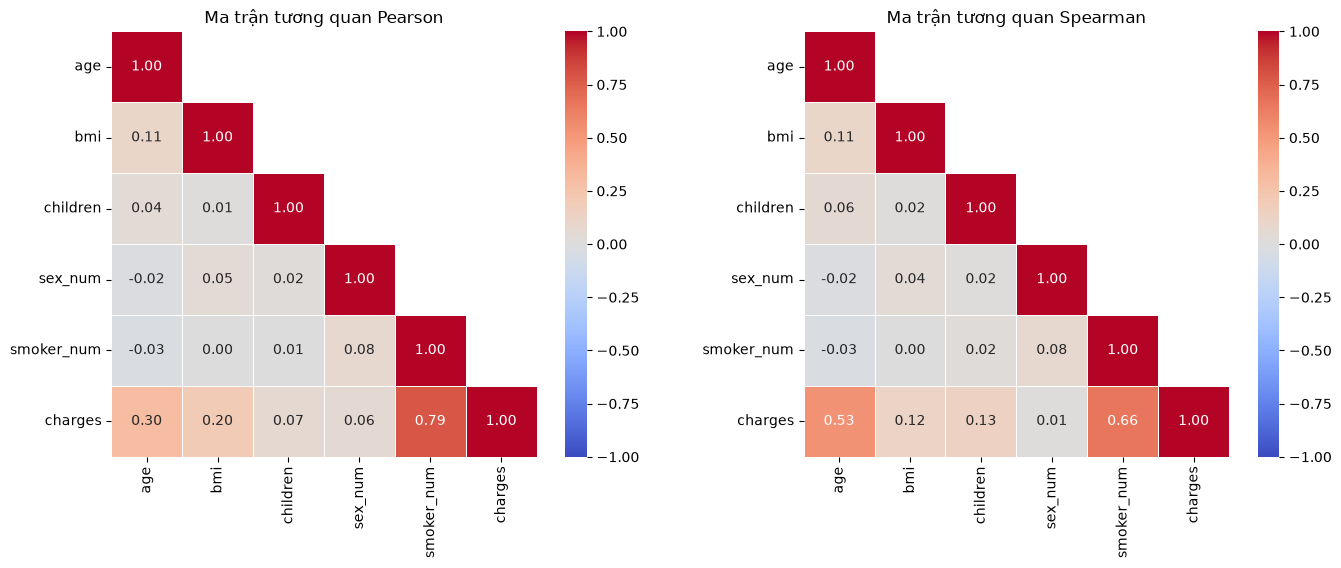

In [25]:
# Import matplotlib để tạo khung hình và hiển thị biểu đồ
import matplotlib.pyplot as plt
# Import seaborn để vẽ heatmap
import seaborn as sns

# Tạo mặt nạ che tam giác trên: np.triu giữ lại phần tam giác trên, k=1 để không che đường chéo
mat_na = np.triu(np.ones_like(ma_tran_pearson, dtype=bool), k=1)

# Tạo khung hình 1 hàng 2 cột để đặt hai heatmap cạnh nhau, kích thước 14 x 5.5 inch
fig, truc = plt.subplots(1, 2, figsize=(14, 5.5))

# Vẽ heatmap Pearson ở ô bên trái
sns.heatmap(ma_tran_pearson, mask=mat_na, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, center=0, square=True, linewidths=0.5, ax=truc[0])
# Đặt tiêu đề cho heatmap bên trái
truc[0].set_title("Ma trận tương quan Pearson")

# Vẽ heatmap Spearman ở ô bên phải với cùng cấu hình để so sánh công bằng
sns.heatmap(ma_tran_spearman, mask=mat_na, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, center=0, square=True, linewidths=0.5, ax=truc[1])
# Đặt tiêu đề cho heatmap bên phải
truc[1].set_title("Ma trận tương quan Spearman")

# Căn chỉnh bố cục để các thành phần không đè lên nhau
plt.tight_layout()
# Hiển thị biểu đồ
plt.show()

**Nhận xét heatmap:**

- **Hàng `charges`** là hàng đáng chú ý nhất. Ô `smoker_num` có màu đỏ đậm nhất (Pearson 0,79 và Spearman 0,66), tiếp theo là ô `age` (Pearson 0,30 và Spearman 0,53). Các ô `bmi`, `children`, `sex_num` có màu rất nhạt, gần trắng, nghĩa là tương quan yếu hoặc gần như không có.
- **So sánh hai heatmap:** ô `age`–`charges` đậm hơn rõ rệt ở heatmap Spearman, còn ô `smoker_num`–`charges` nhạt hơn một chút. Điều này khớp với kết quả đã tính ở mục 4.2.2.
- **Các biến độc lập với nhau:** hầu hết các ô đều gần màu trắng (giá trị tuyệt đối không vượt quá 0,11), cho thấy các biến độc lập gần như **không tương quan** với nhau, nên nguy cơ đa cộng tuyến thấp.
- **Không có ô nào màu xanh đậm:** không có cặp biến nào có tương quan âm đáng kể.
- **Hạn chế:** heatmap chỉ cho thấy **độ mạnh**, chưa cho thấy **hình dạng** của mối quan hệ (thẳng, cong, hay tách thành nhóm). Ta cần biểu đồ phân tán ở mục tiếp theo để kiểm chứng.

### 4.3.2. Biểu đồ phân tán giữa `charges` và các biến `age`, `bmi`, `children`

**Mục đích:** xem **hình dạng thật** của mối quan hệ, vì một con số tương quan có thể che giấu việc dữ liệu cong, tách thành nhiều nhóm hoặc có ngoại lai.

**Lý do chọn biểu đồ:**

- **Scatter plot + đường hồi quy** (cho `age`, `bmi`): mỗi chấm là một người; đường đỏ là đường thẳng khớp nhất với dữ liệu. Độ dốc đường đỏ cho biết dấu của $r$, độ phân tán quanh đường cho biết độ mạnh.
- **Boxplot** (cho `children`): `children` chỉ nhận 6 giá trị (0 đến 5) nên scatter plot sẽ bị các chấm chồng lên nhau thành các cột dọc. Boxplot theo từng mức cho thấy rõ phân phối của `charges` ở mỗi mức số con.

**Giải thích các tham số chính:**

- `sns.regplot(...)`: vẽ scatter và đường hồi quy tuyến tính trong một lệnh.
- `scatter_kws={"alpha": 0.35, "s": 18}`: chấm hơi trong suốt (`alpha`) và nhỏ (`s`) để thấy những chỗ có nhiều điểm chồng nhau.
- `line_kws={"color": "red"}`: tô đường hồi quy màu đỏ.
- `showfliers=False`: ẩn các điểm ngoại lai mặc định của boxplot vì ta sẽ vẽ toàn bộ điểm thật bằng `stripplot`.
- `sns.stripplot(...)`: vẽ từng điểm dữ liệu thật phủ lên boxplot.

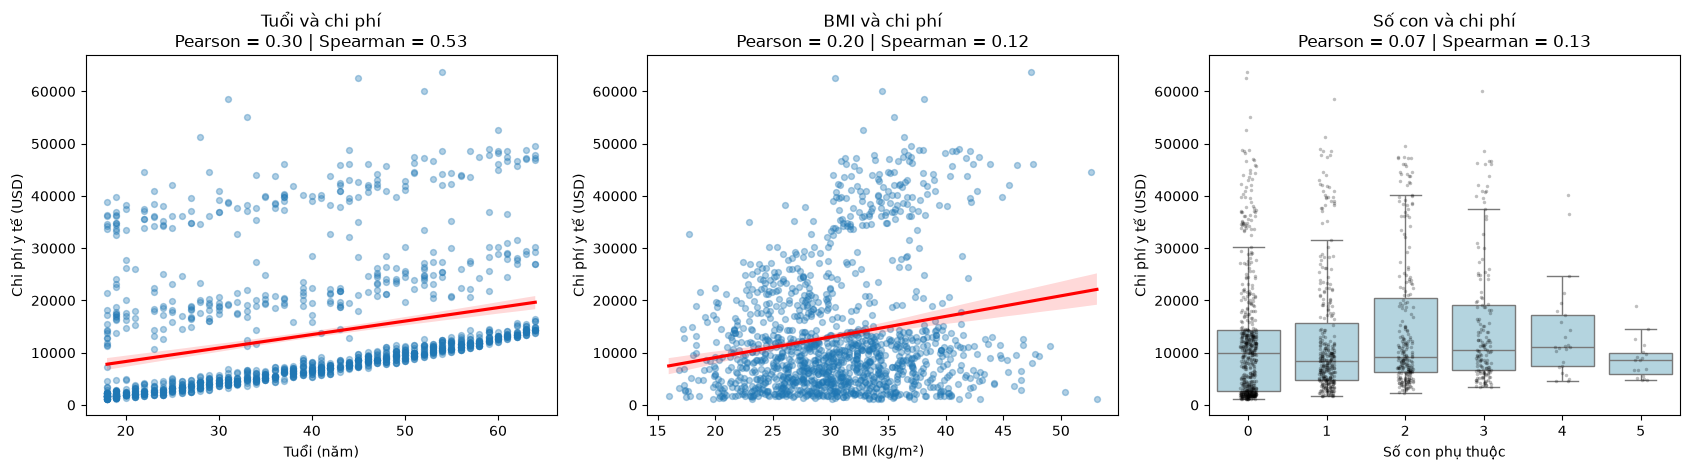

In [26]:
# Tạo khung hình 1 hàng 3 cột, kích thước 17 x 4.8 inch
fig, truc = plt.subplots(1, 3, figsize=(17, 4.8))

# ---- Biểu đồ 1: age - charges ----
# Vẽ scatter và đường hồi quy; alpha làm chấm trong suốt, s là kích thước chấm
sns.regplot(data=df, x="age", y="charges", scatter_kws={"alpha": 0.35, "s": 18},
            line_kws={"color": "red"}, ax=truc[0])
# Đặt tiêu đề kèm hai hệ số lấy từ hai ma trận đã tính ở 4.2.1 và 4.2.2
truc[0].set_title(f"Tuổi và chi phí\nPearson = {ma_tran_pearson.loc['age', 'charges']:.2f}"
                  f" | Spearman = {ma_tran_spearman.loc['age', 'charges']:.2f}")
# Đặt nhãn trục x và trục y
truc[0].set_xlabel("Tuổi (năm)")
truc[0].set_ylabel("Chi phí y tế (USD)")

# ---- Biểu đồ 2: bmi - charges ----
# Vẽ scatter và đường hồi quy cho bmi
sns.regplot(data=df, x="bmi", y="charges", scatter_kws={"alpha": 0.35, "s": 18},
            line_kws={"color": "red"}, ax=truc[1])
# Đặt tiêu đề kèm hai hệ số của cặp bmi - charges
truc[1].set_title(f"BMI và chi phí\nPearson = {ma_tran_pearson.loc['bmi', 'charges']:.2f}"
                  f" | Spearman = {ma_tran_spearman.loc['bmi', 'charges']:.2f}")
# Đặt nhãn trục x và trục y
truc[1].set_xlabel("BMI (kg/m²)")
truc[1].set_ylabel("Chi phí y tế (USD)")

# ---- Biểu đồ 3: children - charges ----
# Vẽ boxplot charges theo từng mức số con, ẩn điểm ngoại lai mặc định
sns.boxplot(data=df, x="children", y="charges", color="lightblue", showfliers=False, ax=truc[2])
# Phủ các điểm dữ liệu thật lên boxplot, alpha thấp để thấy mật độ điểm
sns.stripplot(data=df, x="children", y="charges", color="black", alpha=0.25, size=2.5, ax=truc[2])
# Đặt tiêu đề kèm hai hệ số của cặp children - charges
truc[2].set_title(f"Số con và chi phí\nPearson = {ma_tran_pearson.loc['children', 'charges']:.2f}"
                  f" | Spearman = {ma_tran_spearman.loc['children', 'charges']:.2f}")
# Đặt nhãn trục x và trục y
truc[2].set_xlabel("Số con phụ thuộc")
truc[2].set_ylabel("Chi phí y tế (USD)")

# Căn chỉnh bố cục để các biểu đồ không đè lên nhau
plt.tight_layout()
# Hiển thị biểu đồ
plt.show()

**Nhận xét biểu đồ:**

- **`age` và `charges`:** chi phí tăng đều theo tuổi, nhưng các điểm không nằm quanh một đường thẳng mà **tách thành ba dải** gần song song (khoảng 1.000–15.000 USD, 15.000–30.000 USD và 35.000–50.000 USD). Đường hồi quy màu đỏ nằm giữa các dải nên không khớp với dải nào, kể cả dải thấp là dải đông người nhất. Vì vậy Pearson (0,30) thấp hơn Spearman (0,53): trong từng dải chi phí tăng theo tuổi khá đều (quan hệ đơn điệu), nhưng khoảng cách dọc giữa các dải làm tăng phương sai của `charges` và kéo Pearson xuống.
- **`bmi` và `charges`:** phần lớn điểm nằm ở mức chi phí thấp với mọi giá trị BMI, cộng với một cụm chi phí cao (30.000–50.000 USD) chỉ xuất hiện khi BMI từ khoảng 28–30 trở lên. Quan hệ giống một "bước nhảy" hơn là đường thẳng, và Pearson (0,20) chủ yếu do cụm này tạo ra nên lớn hơn Spearman (0,12).
- **`children` và `charges`:** trung vị gần như đi ngang từ 0 đến 5 con, cho thấy số con hầu như không làm chi phí thay đổi. Các nhóm 4 và 5 con có rất ít người nên kết quả kém tin cậy.
- **Giả thuyết cần kiểm chứng:** ba dải ở biểu đồ tuổi và cụm chi phí cao ở biểu đồ BMI có thể do cùng một yếu tố gây ra, nhiều khả năng là `smoker`. Mục 4.3.3 sẽ tô màu theo `smoker` để kiểm tra.

### 4.3.3. Biểu đồ phân tán tô màu theo nhóm hút thuốc

**Mục đích:** kiểm chứng giả thuyết ở 4.3.2. Nếu `smoker` là nguyên nhân tạo ra các dải, khi tô màu hai nhóm hút thuốc và không hút thuốc thì các dải sẽ tách màu rõ ràng.

**Lý do chọn biểu đồ:** vẫn dùng scatter plot như 4.3.2 để so sánh trực tiếp, nhưng thêm một chiều thông tin (màu) thay vì vẽ thêm biểu đồ mới.

**Giải thích các lệnh chính:**

- `df["smoker"].map({...})`: đổi giá trị `yes`/`no` thành nhãn tiếng Việt để chú thích dễ đọc.
- `hue=...`: tô màu từng điểm theo nhóm.
- `palette=...`: cố định màu của mỗi nhóm để hai biểu đồ dùng cùng một bảng màu.

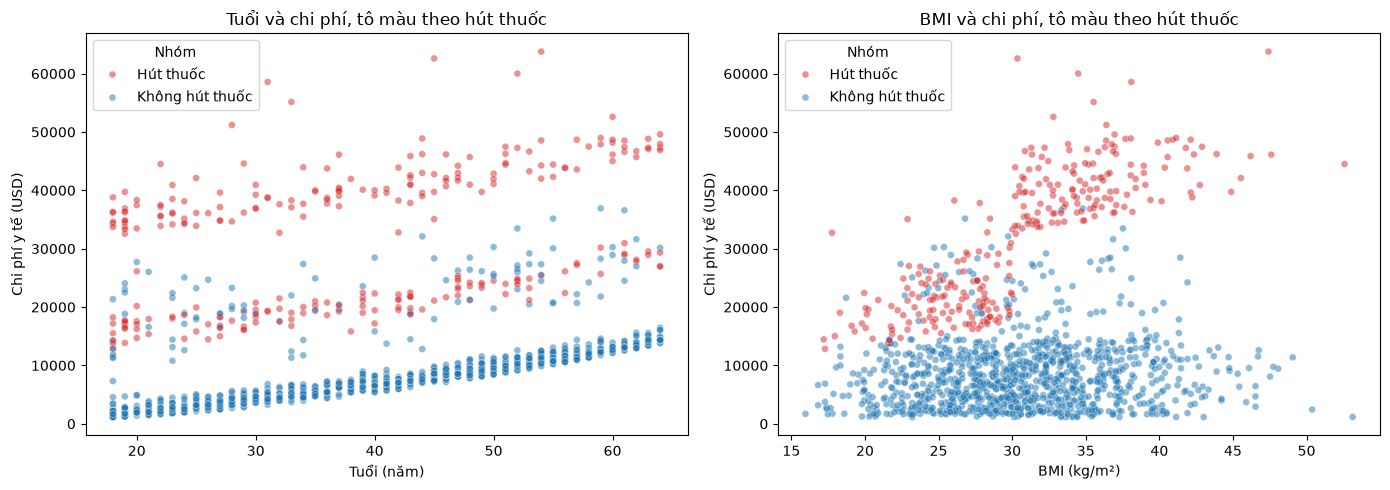

In [27]:
# Tạo cột nhãn tiếng Việt để chú thích (legend) dễ đọc: yes -> "Hút thuốc", no -> "Không hút thuốc"
df["nhom_hut_thuoc"] = df["smoker"].map({"yes": "Hút thuốc", "no": "Không hút thuốc"})

# Bảng màu cố định: nhóm không hút thuốc màu xanh, nhóm hút thuốc màu đỏ
bang_mau = {"Không hút thuốc": "tab:blue", "Hút thuốc": "tab:red"}

# Tạo khung hình 1 hàng 2 cột, kích thước 14 x 5 inch
fig, truc = plt.subplots(1, 2, figsize=(14, 5))

# ---- Biểu đồ 1: age - charges, tô màu theo nhóm hút thuốc ----
# alpha làm chấm trong suốt, s là kích thước chấm, ax chọn ô vẽ bên trái
sns.scatterplot(data=df, x="age", y="charges", hue="nhom_hut_thuoc",
                palette=bang_mau, alpha=0.5, s=25, ax=truc[0])
# Đặt tiêu đề, nhãn trục và tiêu đề chú thích cho biểu đồ bên trái
truc[0].set_title("Tuổi và chi phí, tô màu theo hút thuốc")
truc[0].set_xlabel("Tuổi (năm)")
truc[0].set_ylabel("Chi phí y tế (USD)")
truc[0].legend(title="Nhóm")

# ---- Biểu đồ 2: bmi - charges, tô màu theo nhóm hút thuốc ----
# Vẽ tương tự nhưng trục x là bmi, ax chọn ô vẽ bên phải
sns.scatterplot(data=df, x="bmi", y="charges", hue="nhom_hut_thuoc",
                palette=bang_mau, alpha=0.5, s=25, ax=truc[1])
# Đặt tiêu đề, nhãn trục và tiêu đề chú thích cho biểu đồ bên phải
truc[1].set_title("BMI và chi phí, tô màu theo hút thuốc")
truc[1].set_xlabel("BMI (kg/m²)")
truc[1].set_ylabel("Chi phí y tế (USD)")
truc[1].legend(title="Nhóm")

# Căn chỉnh bố cục để các thành phần không đè lên nhau
plt.tight_layout()
# Hiển thị biểu đồ
plt.show()

**Nhận xét biểu đồ tô màu theo hút thuốc:**

- **`age` và `charges`:** dải thấp nhất (khoảng 1.000–16.000 USD) gần như toàn là người **không hút thuốc** và nằm rất sát một đường thẳng, nghĩa là khi tách nhóm này ra, tuổi và chi phí có quan hệ tuyến tính rõ. Dải cao nhất (khoảng 33.000–50.000 USD) gần như toàn là người **hút thuốc**. Dải giữa (khoảng 15.000–30.000 USD) là dải **hỗn hợp**, có cả hai nhóm, nên `smoker` chưa giải thích hết được ba dải.
- **`bmi` và `charges`:** ở nhóm không hút thuốc, chi phí gần như không đổi theo BMI (đám mây nằm ngang). Ở nhóm hút thuốc, chi phí **tăng vọt khi BMI vượt khoảng 30**: dưới ngưỡng này chi phí chủ yếu ở mức 12.000–30.000 USD, trên ngưỡng này lên 30.000–50.000 USD. Điều này giải thích vì sao dải giữa và dải trên ở biểu đồ tuổi tách nhau.
- **Ý nghĩa với hệ số tương quan:** tương quan gộp của `bmi` với `charges` (Pearson = 0,20) chủ yếu đến từ nhóm hút thuốc, nên con số gộp này **che mất** việc BMI gần như không ảnh hưởng ở nhóm không hút thuốc. Đây là hiệu ứng tương tác giữa `smoker` và `bmi`.
- **Hạn chế:** biểu đồ chỉ cho thấy mối quan hệ, chưa chứng minh nhân quả. Nhóm người không hút thuốc nhưng có chi phí 15.000–30.000 USD cần được xem xét thêm bằng các biến khác (sẽ làm ở phần hồi quy).

### 4.3.4. Tương quan với `charges` trong từng nhóm hút thuốc

**Mục đích:** biểu đồ ở 4.3.3 cho thấy hai nhóm có hình dạng quan hệ rất khác nhau. Ta tính lại Pearson và Spearman **riêng cho từng nhóm** để kiểm chứng bằng số.

**Giải thích các lệnh chính:**

- `df.groupby("nhom_hut_thuoc")`: chia bảng thành hai nhóm nhỏ theo biến hút thuốc.
- Vòng lặp lồng nhau: vòng ngoài duyệt qua từng nhóm, vòng trong duyệt qua từng biến độc lập.
- `smoker_num` không được đưa vào vì trong mỗi nhóm nó chỉ có một giá trị, nên không thể tính tương quan.

In [28]:
# Danh sách biến độc lập cần xét trong từng nhóm (không gồm smoker_num vì mỗi nhóm chỉ có một giá trị của biến này)
bien_doc_lap = ["age", "bmi", "children", "sex_num"]

# Tạo danh sách rỗng để lưu từng dòng kết quả
ket_qua_nhom = []

# Chia bảng theo nhóm hút thuốc; mỗi vòng lặp cho ra tên nhóm và bảng dữ liệu của nhóm đó
for ten_nhom, du_lieu_nhom in df.groupby("nhom_hut_thuoc"):
    # Duyệt qua từng biến độc lập trong nhóm hiện tại
    for bien in bien_doc_lap:
        # Tính Pearson giữa biến này và charges, chỉ dùng người trong nhóm
        r_p = stats.pearsonr(du_lieu_nhom[bien], du_lieu_nhom["charges"])[0]
        # Tính Spearman giữa biến này và charges, chỉ dùng người trong nhóm
        r_s = stats.spearmanr(du_lieu_nhom[bien], du_lieu_nhom["charges"])[0]
        # Lưu một dòng kết quả (dạng từ điển) vào danh sách
        ket_qua_nhom.append({
            "Nhóm": ten_nhom,                 # tên nhóm hút thuốc
            "Biến": bien,                     # tên biến độc lập
            "n": len(du_lieu_nhom),           # số người trong nhóm
            "Pearson": round(r_p, 3),         # hệ số Pearson làm tròn 3 chữ số
            "Spearman": round(r_s, 3),        # hệ số Spearman làm tròn 3 chữ số
        })

# Chuyển danh sách thành bảng, dùng hai cột Nhóm và Biến làm chỉ mục
bang_nhom = pd.DataFrame(ket_qua_nhom).set_index(["Nhóm", "Biến"])

# In bảng kết quả
print(bang_nhom)

                             n  Pearson  Spearman
Nhóm            Biến                             
Hút thuốc       age        274    0.368     0.452
                bmi        274    0.806     0.834
                children   274    0.036     0.087
                sex_num    274    0.101     0.097
Không hút thuốc age       1064    0.628     0.821
                bmi       1064    0.084     0.105
                children  1064    0.139     0.181
                sex_num   1064   -0.056    -0.073


**Nhận xét kết quả (tương quan theo nhóm hút thuốc):**

| Biến | Gộp (Pearson / Spearman) | Không hút thuốc (n = 1064) | Hút thuốc (n = 274) |
|---|---|---|---|
| `age` | 0,299 / 0,534 | 0,628 / 0,821 | 0,368 / 0,452 |
| `bmi` | 0,198 / 0,119 | 0,084 / 0,105 | 0,806 / 0,834 |
| `children` | 0,068 / 0,133 | 0,139 / 0,181 | 0,036 / 0,087 |
| `sex_num` | 0,057 / 0,009 | −0,056 / −0,073 | 0,101 / 0,097 |

- **`bmi`:** ở nhóm hút thuốc, tương quan rất mạnh (Pearson = 0,806; R² ≈ 0,65), còn ở nhóm không hút thuốc gần như bằng 0 (0,084). Hệ số gộp 0,198 là kết quả "pha trộn" của hai tình huống khác hẳn nhau nên che mất mối quan hệ thật. Đây là bằng chứng bằng số cho **hiệu ứng tương tác** giữa `smoker` và `bmi` đã thấy ở biểu đồ.
- **`age`:** tương quan mạnh nhất ở nhóm không hút thuốc (Pearson = 0,628; Spearman = 0,821). Khi tách riêng, tuổi và chi phí gần như tuyến tính. Ở nhóm hút thuốc tương quan thấp hơn (0,368) vì chi phí của nhóm này còn biến thiên mạnh theo BMI.
- **`children`:** tăng nhẹ so với hệ số gộp ở nhóm không hút thuốc (Spearman = 0,181) nhưng vẫn yếu (R² dưới 4%).
- **`sex_num`:** hệ số đổi dấu giữa hai nhóm và đều rất nhỏ. Hệ số gộp dương một phần do nam hút thuốc nhiều hơn nữ một chút (tương quan `sex_num`–`smoker_num` = 0,076), tức là có yếu tố gây nhiễu từ `smoker`. Chưa đủ cơ sở để kết luận giới tính ảnh hưởng đến chi phí.
- **Bài học:** hệ số tương quan gộp có thể gây hiểu lầm khi dữ liệu gồm các nhóm có hành vi khác nhau, nên cần xét theo nhóm. Các hệ số theo nhóm ở đây chỉ mang tính khám phá vì chưa kiểm định p-value cho từng nhóm.

## 4.4. Nhận xét về ý nghĩa thực tiễn của các mối tương quan

**1. Hút thuốc là yếu tố liên quan mạnh nhất đến chi phí.** Hệ số Pearson giữa `smoker_num` và `charges` là 0,787 (R² ≈ 0,62): riêng việc có hút thuốc hay không đã đi cùng khoảng 62% biến thiên của chi phí trong mẫu. Với công ty bảo hiểm, đây là yếu tố phân loại rủi ro quan trọng nhất trong bộ dữ liệu.

**2. Tuổi tăng thì chi phí tăng đều.** Quan hệ này rõ nhất ở nhóm không hút thuốc (Spearman = 0,821), nên tuổi là yếu tố dễ dự đoán và phù hợp để định giá phí bảo hiểm theo độ tuổi.

**3. BMI chỉ quan trọng ở nhóm hút thuốc.** Hệ số gộp (0,198) cho thấy BMI yếu, nhưng trong nhóm hút thuốc hệ số lên tới 0,806, và biểu đồ cho thấy chi phí tăng vọt khi BMI vượt khoảng 30. Ý nghĩa thực tiễn: nhóm vừa hút thuốc vừa béo phì là nhóm rủi ro chi phí cao nhất.

**4. Số con và giới tính gần như không có ý nghĩa thực tiễn.** Các hệ số đều nhỏ (R² dưới 1% ở mức gộp), dù một số có p-value nhỏ hơn 0,05 do cỡ mẫu lớn.

**Hạn chế khi diễn giải:**

- Tương quan không đồng nghĩa với nhân quả.
- Pearson chỉ đo quan hệ tuyến tính và nhạy với ngoại lai; `charges` lệch phải nên cần xem cả Spearman.
- Hệ số tính trên từng cặp biến, chưa loại bỏ ảnh hưởng của các biến còn lại. Việc này sẽ được xử lý ở phần hồi quy đa biến.

**Gợi ý cho phần hồi quy:** nên đưa `smoker`, `age`, `bmi` vào mô hình và cân nhắc thêm số hạng tương tác `smoker × bmi`.